# Milestone 2: from original sources to explainable analysis data
**Mapping the U.S. AI Job Market · SecB2 Group 07**

This notebook is the report/video walkthrough. Saved outputs show an executed run against our real MongoDB and PostgreSQL databases. Open the accompanying HTML export to read without installing Python or entering credentials.

**Run All reads both databases and saves local figures; it does not rebuild or delete database data.** Production ingestion commands are at the end. Select the repository's `.venv` interpreter to rerun.

We retain three complementary datasets: BLS OEWS (employment/wages), O*NET (occupation/skill references), and Headcount (nested job JSON). Adzuna was replaced by Headcount after Milestone 1. Our ten-state title-capped sample supports descriptive comparisons, not representative national vacancy estimates.

## 1. Why use both databases?
Course requirements C10–13 preserve raw data and require structured data in PostgreSQL. D17 permits flattening semi-structured data; D19 explicitly permits MongoDB queries for JSON. They do **not** require deleting relational derivatives when the raw source is JSON.

We therefore keep original Headcount pages in MongoDB, perform initial cleaning with aggregation pipelines, and retain PostgreSQL derivatives for SOC/metro/skill integration. The two processing paths start from identical original files and are reconciled. The existing SQL pipeline is not claimed to have been loaded from the new MongoDB summaries.

In [1]:
from pathlib import Path
import json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/pipeline_common.py').exists())
sys.path.insert(0, str(ROOT/'scripts'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, JSON, Markdown
from sqlalchemy import text
from ingest_headcount_mongo import mongo_database
from mongo_pipeline import occurrence_stages, selection_stages, merge_stage
from pipeline_common import database_engine
from demo_visuals import architecture, relational_schema, cleaning_counts
pd.set_option('display.max_colwidth', 85)
pd.set_option('display.max_columns', 15)
plt.rcParams.update({'font.size':11, 'figure.dpi':110})
engine = database_engine()
mongo_client, db = mongo_database()
mongo_run = json.loads((ROOT/'reports/mongodb_ingestion.json').read_text(encoding='utf-8'))
mongo_qa = json.loads((ROOT/'reports/mongodb_quality.json').read_text(encoding='utf-8'))
pg_qa = json.loads((ROOT/'reports/data_quality.json').read_text(encoding='utf-8'))
access = json.loads((ROOT/'reports/data_access.json').read_text(encoding='utf-8'))
snapshot, clean_version = mongo_run['source_snapshot'], mongo_run['clean_version']
scope = {'source_snapshot':snapshot, 'clean_version':clean_version}
FIGURES = ROOT/'docs/figures'
def sql(query, params=None):
    with engine.connect() as connection:
        connection.execute(text('SET TRANSACTION READ ONLY'))
        return pd.read_sql(text(query), connection, params=params)
assert all(mongo_qa['checks'].values()), 'Resolve MongoDB audit failures first.'
assert all(pg_qa['checks'].values()), 'Resolve PostgreSQL audit failures first.'
assert sql('SELECT batch_id FROM audit.active_batch').iloc[0,0] == mongo_qa['postgres_batch_id']
print('Connected without displaying credentials.')
print('MongoDB database:', db.name, '| PostgreSQL database:', engine.url.database)
print('Source snapshot:', snapshot, '| Mongo cleaning version:', clean_version)

Connected without displaying credentials.
MongoDB database: ai_job_market | PostgreSQL database: ai_job_market
Source snapshot: hc_source_eea46d64c7da954d7bab | Mongo cleaning version: mc_e6b15bd4d4ef57ed176b


,system,location,purpose
0,Local original files,data/downloads/ + data/raw/,Original ZIP/XLSX/CSV/JSON and checkpoints
1,MongoDB,ai_job_market.raw_pages,Original nested JSON page payloads
2,MongoDB,ai_job_market.clean_job_summaries,Canonical job selection and initial document cleaning
3,MongoDB,ai_job_market.clean_pay_ranges,Typed salary ranges and eligibility flags
4,PostgreSQL,ai_job_market.raw.*,Government source cells as TEXT
5,PostgreSQL,ai_job_market.staging.*,Versioned flattened Headcount snapshots
6,PostgreSQL,ai_job_market.clean.* + serving.*,"Typed data, entity resolution and integration"


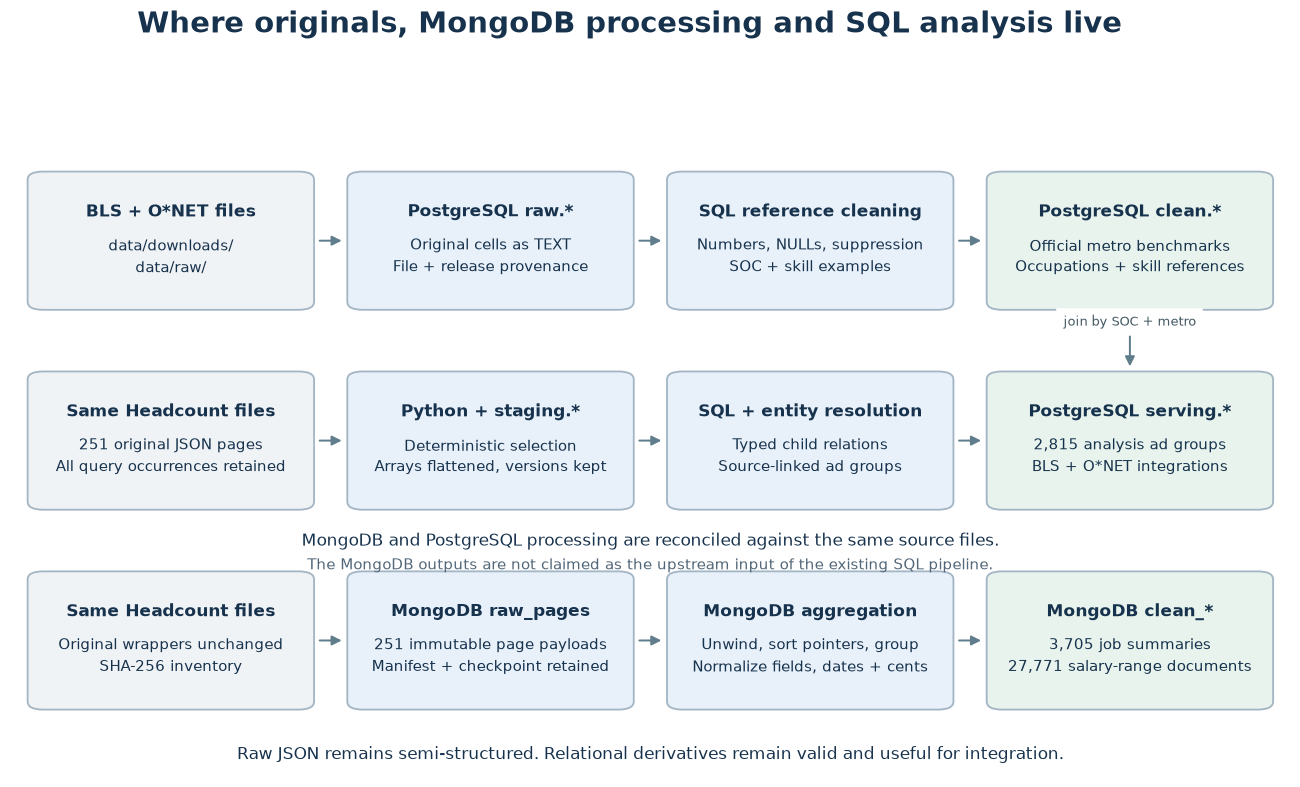

In [2]:
display(pd.DataFrame([
    {'system':'Local original files','location':'data/downloads/ + data/raw/','purpose':'Original ZIP/XLSX/CSV/JSON and checkpoints'},
    {'system':'MongoDB','location':db.name+'.raw_pages','purpose':'Original nested JSON page payloads'},
    {'system':'MongoDB','location':db.name+'.clean_job_summaries','purpose':'Canonical job selection and initial document cleaning'},
    {'system':'MongoDB','location':db.name+'.clean_pay_ranges','purpose':'Typed salary ranges and eligibility flags'},
    {'system':'PostgreSQL','location':'ai_job_market.raw.*','purpose':'Government source cells as TEXT'},
    {'system':'PostgreSQL','location':'ai_job_market.staging.*','purpose':'Versioned flattened Headcount snapshots'},
    {'system':'PostgreSQL','location':'ai_job_market.clean.* + serving.*','purpose':'Typed data, entity resolution and integration'},
]))
display(architecture(FIGURES))
plt.close('all')

## 2. Inspect the original semi-structured data
**Before cleaning:** a page contains query metadata, a `response.data` array, field-state wrappers, and nested location/source-posting/money arrays. JSON remains semi-structured after we create relational copies. This preview uses one real job and shortens its description only for display.

In [3]:
original_page = db.raw_pages.find_one({'source_snapshot':snapshot, 'payload.response.data.0':{'$exists':True}},
    {'source_file':1, 'source_sha256':1, 'payload.response.data':{'$slice':1}})
original_job = original_page['payload']['response']['data'][0]
print('Original file:', original_page['source_file'])
print('File SHA-256:', original_page['source_sha256'])
preview = {k:original_job.get(k) for k in ['job_id','title','employer_name','work_arrangement']}
preview['description'] = {'state':original_job['description'].get('state'),
                          'value_preview':(original_job['description'].get('value') or '')[:240]}
preview['first_location'] = (original_job.get('locations') or [None])[0]
preview['first_source_money'] = (original_job.get('postings') or [{}])[0].get('money',[])[:1]
display(JSON(preview))

Original file: data/raw/headcount_10states/states/CA/ai_engineer/page_0001.json
File SHA-256: 128229f309aa93108e7aa5fd13ec70683931051294bfa568c95560e00a0b79e8


<IPython.core.display.JSON object>

## 3. MongoDB: expand pages and count repeated queries
`$unwind` exposes each returned occurrence. The same job can be found by several state/title queries, so an occurrence is not a unique job. Empty responses must also stay in raw storage.

In [4]:
page_counts = list(db.raw_pages.aggregate([
    {'$match':{'source_snapshot':snapshot}},
    {'$project':{'returned':{'$size':'$payload.response.data'}}},
    {'$group':{'_id':None,'page_files':{'$sum':1},'returned_occurrences':{'$sum':'$returned'},
                'empty_pages':{'$sum':{'$cond':[{'$eq':['$returned',0]},1,0]}}}}
]))[0]
display(pd.DataFrame([{k:v for k,v in page_counts.items() if k!='_id'}]))
repeated = list(db.raw_pages.aggregate(occurrence_stages(snapshot) + [
    {'$group':{'_id':'$job.job_id','returned_occurrences':{'$sum':1}}},
    {'$match':{'returned_occurrences':{'$gt':1}}},
    {'$sort':{'returned_occurrences':-1,'_id':1}}, {'$limit':5}
], allowDiskUse=False))
display(pd.DataFrame(repeated).rename(columns={'_id':'job_id'}))

,page_files,returned_occurrences,empty_pages
0,251,5635,5


,job_id,returned_occurrences
0,04d36199-2663-4cce-a07e-57e5e343b12e,10
1,16be56e1-d77e-47c3-9816-5c4a6ca00d1d,10
2,1c52dab9-c767-4645-a8bd-a421f12f5415,10
3,2ae974e9-d519-43f2-94e3-38204fa29dc2,10
4,4a0e5f39-ebbe-4e9b-bff9-2f8878025e61,10


## 4. MongoDB: select a deterministic job version
Sort by source update time, curation time, source-file path and array index; then take the first record per job ID. Query matches and occurrence counts remain attached. We sort lightweight pointers before fetching text/arrays because this Atlas tier has a 32 MB in-memory sort limit. The raw pages are unchanged.

In [5]:
selection_pipeline = selection_stages(snapshot)
display(JSON([stage for stage in selection_pipeline if '$sort' in stage or '$group' in stage]))
selected = list(db.raw_pages.aggregate(selection_pipeline + [
    {'$project':{'_id':0,'job_id':1,'source_file':1,'record_index':1,'updated_utc':1,'occurrence_count':1}},
    {'$limit':5}
], allowDiskUse=False))
display(pd.DataFrame(selected))
print('Persisted canonical job documents:', db.clean_job_summaries.count_documents(scope))

<IPython.core.display.JSON object>

,source_file,record_index,job_id,updated_utc,occurrence_count
0,data/raw/headcount_10states/states/MA/machine_learning_engineer/page_0003.json,12,8b1d89bd-e6f7-4b66-930f-6c51c939be1e,2026-11-16 18:29:01.448000+00:00,1
1,data/raw/headcount_10states/states/PA/ai_engineer/page_0001.json,14,eb571ede-cd10-4e4d-a326-09b6e0484feb,2026-11-19 18:07:13.623000+00:00,1
2,data/raw/headcount_10states/states/VA/ai_engineer/page_0004.json,20,9a6cb727-df88-48ef-a71d-71739ccb1bc7,2026-11-19 15:09:36.416000+00:00,2
3,data/raw/headcount_10states/states/CA/data_scientist/page_0003.json,4,9d9ca63e-a8bb-4b6d-b5ee-939f31078d74,2026-11-19 18:31:23.141000+00:00,1
4,data/raw/headcount_10states/states/VA/data_scientist/page_0002.json,20,0beb2691-788c-4aad-9a25-52f3f3c49029,2026-11-20 05:59:53.818000+00:00,1


Persisted canonical job documents: 3705


## 5. MongoDB: normalize text, types and missingness
**After initial document cleaning:** titles/text have normalized whitespace, observation dates are BSON dates, and locations remain a structured array. `source_omitted` and `extraction_failed` remain distinct; missing descriptions are NULL, not fabricated text or evidence of absent skills. PostgreSQL's text path additionally strips HTML/unescapes entities using the shared Python rules.

In [6]:
normalized_job = db.clean_job_summaries.find_one(dict(scope, job_id=original_job['job_id']))
display(pd.DataFrame([
    {'field':'title','before':original_job['title'],'after':normalized_job['title']},
    {'field':'first_seen','before':original_job['job_first_seen_at'],'after':normalized_job['first_seen_utc']},
    {'field':'description state','before':original_job['description'].get('state'),'after':normalized_job['description_state']},
    {'field':'location shape','before':'Nested field-state array','after':str(len(normalized_job['locations']))+' normalized entries'},
]))
missingness = list(db.clean_job_summaries.aggregate([
    {'$match':scope}, {'$group':{'_id':'$description_state','provider_records':{'$sum':1}}},
    {'$sort':{'provider_records':-1}}
]))
display(pd.DataFrame(missingness).rename(columns={'_id':'description_state'}))
missing_example = db.clean_job_summaries.find_one(dict(scope,description_state='extraction_failed'),
    {'_id':0,'job_id':1,'description_state':1,'description':1})
display(missing_example)

,field,before,after
0,title,"{'state': 'known', 'value': 'Senior AI Engineer, AI.x'}","Senior AI Engineer, AI.x"
1,first_seen,2026-11-20T08:44:43.004Z,2026-11-20 08:44:43.004000+00:00
2,description state,known,known
3,location shape,Nested field-state array,1 normalized entries


,description_state,provider_records
0,known,3680
1,extraction_failed,15
2,source_omitted,10


{'description': None,
 'description_state': 'extraction_failed',
 'job_id': '0496719e-f1fb-4344-bb1f-2e8702151987'}

## 6. MongoDB: source money to exact dollar ranges
The production aggregation unwinds source postings and money arrays, uses `$convert` to Decimal128, divides cents by 100, and applies explicit validity/currency/period/source-status rules. Annual USD ranges outside the review bounds, incomplete ranges and unknown periods stay stored with flags. They are not silently repaired.

In [7]:
example_range = (db.clean_pay_ranges.find_one(dict(scope,job_id=original_job['job_id'],salary_eligible=True))
                 or db.clean_pay_ranges.find_one(dict(scope,salary_eligible=True)))
page = db.raw_pages.find_one({'_id':example_range['raw_page_id']},{'payload.response.data':1})
job = page['payload']['response']['data'][example_range['record_index']]
posting = job['postings'][example_range['posting_index']]
raw_money = posting.get('money',[])[example_range['money_index']]
display(pd.DataFrame([
    {'field':'minimum','before':raw_money.get('min_cents'),'before_type':'integer cents',
     'after':str(example_range['salary_min']),'after_type':'Decimal128 dollars'},
    {'field':'maximum','before':raw_money.get('max_cents'),'before_type':'integer cents',
     'after':str(example_range['salary_max']),'after_type':'Decimal128 dollars'},
    {'field':'period','before':raw_money.get('period'),'before_type':'source evidence',
     'after':example_range['period'],'after_type':'retained; never guessed'},
    {'field':'primary comparison eligible','before':'Not yet evaluated','before_type':'',
     'after':str(example_range['salary_eligible']),'after_type':'boolean'},
]))
# An actual, read-only MongoDB conversion preview for this original page/job.
cents_preview = list(db.raw_pages.aggregate([
    {'$match':{'_id':example_range['raw_page_id']}}, {'$unwind':'$payload.response.data'},
    {'$match':{'payload.response.data.job_id':example_range['job_id']}},
    {'$unwind':'$payload.response.data.postings'},
    {'$unwind':'$payload.response.data.postings.money'},
    {'$project':{'_id':0,'min_cents':'$payload.response.data.postings.money.min_cents',
        'min_dollars':{'$divide':[{'$convert':{'input':'$payload.response.data.postings.money.min_cents',
            'to':'decimal','onError':None,'onNull':None}},100]},
        'period':'$payload.response.data.postings.money.period'}}, {'$limit':3}
]))
display(pd.DataFrame(cents_preview))

,field,before,before_type,after,after_type
0,minimum,22000000,integer cents,220000,Decimal128 dollars
1,maximum,28000000,integer cents,280000,Decimal128 dollars
2,period,year,source evidence,year,retained; never guessed
3,primary comparison eligible,Not yet evaluated,,True,boolean


,min_cents,min_dollars,period
0,22000000,220000,year


In [8]:
salary_before_after = sql("""
    SELECT DISTINCT ON (p.salary_quality) p.salary_quality,
      m.min_cents AS source_min_cents, m.max_cents AS source_max_cents,
      p.salary_min AS cleaned_min_dollars, p.salary_max AS cleaned_max_dollars,
      p.currency, p.period, p.valid_range, p.salary_eligible
    FROM staging.headcount_pay_ranges m JOIN clean.pay_ranges p
      ON m.batch_id=p.batch_id AND m.job_id=p.job_id
      AND m.posting_index::integer=p.posting_index AND m.money_index::integer=p.money_index
    ORDER BY p.salary_quality,p.job_id,p.posting_index,p.money_index
""")
display(salary_before_after)
print('PostgreSQL and MongoDB agree on every salary row key, value and eligibility flag:',
      mongo_qa['checks']['salary_values_and_flags_equal'])

,salary_quality,source_min_cents,source_max_cents,cleaned_min_dollars,cleaned_max_dollars,currency,period,valid_range,salary_eligible
0,annual_usd_valid,11500000,13500000,115000.00,135000.00,USD,year,True,True
1,incomplete_or_invalid_range,8000000,,80000.00,NaN,USD,year,False,False
2,nonannual_or_unknown_period,3027,4565,30.27,45.65,USD,hour,True,False
3,non_usd_or_unknown_currency,12000000,18006000,120000.00,180060.00,,unknown,True,False
4,outlier_review,1200000,1600000,12000.00,16000.00,USD,year,True,False
5,unverified_pay_state,6000000,7000000,60000.00,70000.00,USD,hour,True,False


PostgreSQL and MongoDB agree on every salary row key, value and eligibility flag: True


## 7. MongoDB arrays to relational child tables
A provider job is not a single location or a single salary range. `$unwind` produces entries; foreign/unknown locations remain inspectable. A state query is collection metadata, not permission to assign every result to that state. MongoDB retains source CBSA codes; PostgreSQL verifies them against the pinned BLS metro vintage.

,job_id,city,source_region,country,state_us,source_cbsa
0,b00dfc3f-b80a-44e1-93fa-7ae65e8013e0,San Francisco,US-CA,US,CA,41860


,metro_match_status,location_entries
0,no_metro_code,2100
1,non_us_or_unknown_country,539
2,verified_code,18696


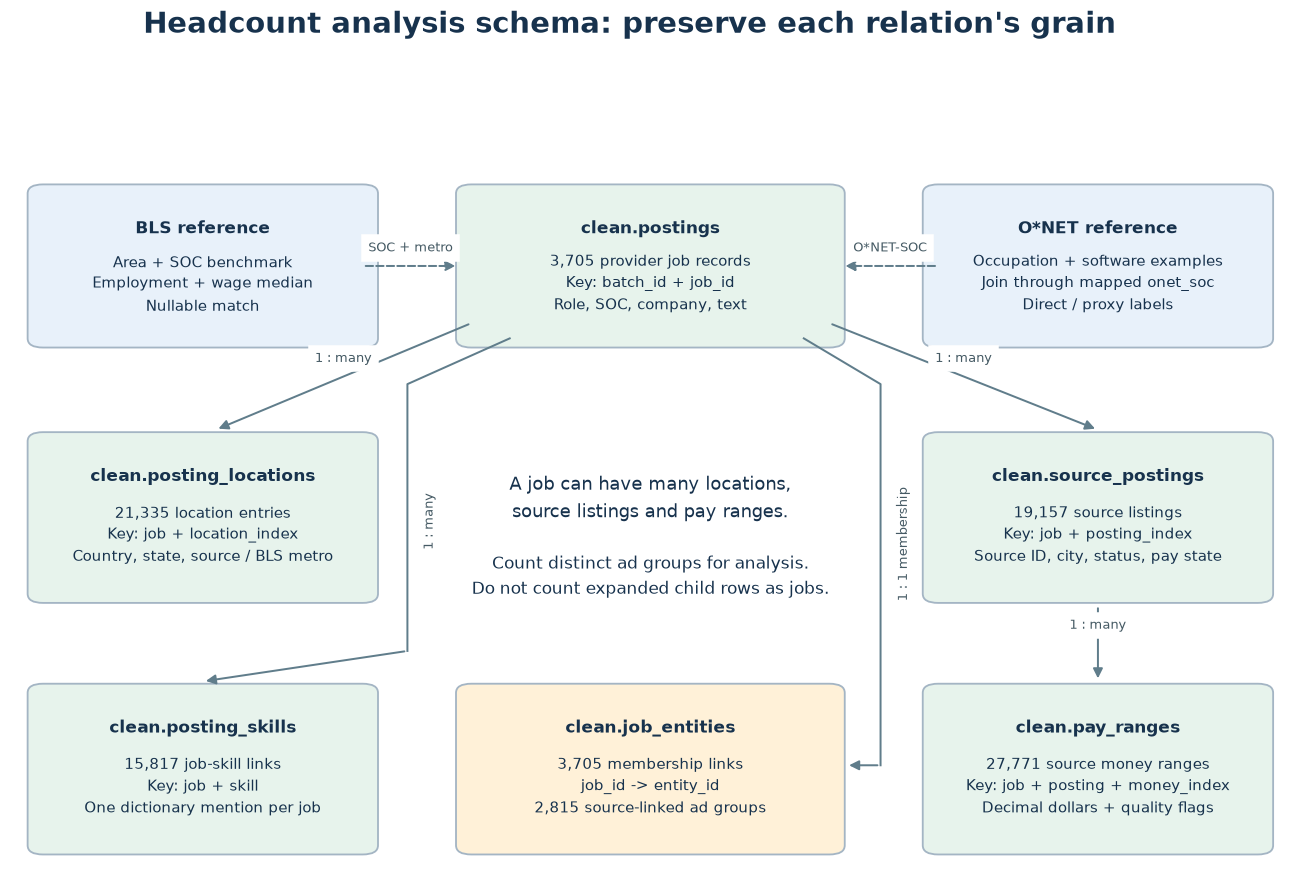

In [9]:
locations = list(db.clean_job_summaries.aggregate([
    {'$match':dict(scope,job_id=original_job['job_id'])}, {'$unwind':'$locations'},
    {'$project':{'_id':0,'job_id':1,'city':'$locations.city','source_region':'$locations.region',
      'country':'$locations.country','state_us':'$locations.state_us','source_cbsa':'$locations.source_cbsa'}},
    {'$limit':6}
]))
display(pd.DataFrame(locations))
display(sql('SELECT metro_match_status,count(*) AS location_entries FROM clean.posting_locations GROUP BY 1 ORDER BY 1'))
display(relational_schema(FIGURES))
plt.close('all')

## 8. SQL: preserve BLS source symbols, then type valid numbers
Before cleaning, even valid numbers are TEXT in `raw.*`. Symbols and blanks are source evidence. The inline CASE below illustrates the same strict numeric rule used by `clean.number`; suppression/top coding become numeric NULL with a separate status, never zero. Both metro and nonmetro workbooks remain stored; only detailed metro observations form the primary benchmark.

In [10]:
bls_before_after = sql("""
    WITH examples AS (
        SELECT DISTINCT ON (a_median) area,occ_code,tot_emp,a_median
        FROM raw.oews_metro WHERE a_median IN ('*','**','#','')
        UNION ALL
        SELECT area,occ_code,tot_emp,a_median FROM raw.oews_metro
        WHERE area='41860' AND occ_code='15-2051'
    )
    SELECT area,occ_code,tot_emp AS raw_employment,a_median AS raw_median,
      pg_typeof(a_median)::text AS raw_type,
      CASE WHEN btrim(replace(replace(a_median,',',''),'$','')) ~ '^[+-]?[0-9]+([.][0-9]+)?$'
           THEN btrim(replace(replace(a_median,',',''),'$',''))::numeric END AS typed_median,
      CASE WHEN a_median='#' THEN 'top_coded'
           WHEN a_median IN ('*','**') THEN 'suppressed_or_unavailable'
           WHEN a_median='' THEN 'missing' ELSE 'numeric' END AS reason
    FROM examples ORDER BY reason,area
""")
display(bls_before_after)
display(sql("SELECT area_type,o_group,count(*) AS source_rows FROM clean.bls_oews GROUP BY 1,2 ORDER BY 1,2"))

,area,occ_code,raw_employment,raw_median,raw_type,typed_median,reason
0,41860,15-2051,10460,170110,text,170110.0,numeric
1,0100001,27-2022,90,*,text,NaN,suppressed_or_unavailable
2,1700002,29-1151,50,#,text,NaN,top_coded


,area_type,o_group,source_rows
0,4,detailed,141015
1,4,major,8615
2,4,total,393
3,6,detailed,45542
4,6,major,3010
5,6,total,137


## 9. SQL: normalize O*NET examples and join occupation codes
Codes remain text so punctuation and leading zeros are preserved. Technology examples become lowercase/trimmed strings; Y/N flags become nullable booleans. O*NET's `.01` extension maps to the corresponding six-digit BLS SOC. Five role mappings are proxies and remain labelled; generic analyst and AI-product-manager benchmarks are especially approximate.

In [11]:
display(sql("""
    SELECT r.o_net_soc_code,r.workplace_example AS original_example,
           lower(btrim(r.workplace_example)) AS cleaned_example,
           r.in_demand AS original_flag,
           CASE btrim(r.in_demand) WHEN 'Y' THEN true WHEN 'N' THEN false END AS cleaned_flag
    FROM raw.onet_software_skills r
    WHERE r.o_net_soc_code='15-2051.00' AND lower(r.workplace_example) LIKE '%python%'
    LIMIT 5
"""))
display(sql("""
    SELECT r.role,r.bls_soc,r.onet_soc,o.occupation,r.occupation_mapping,r.notes
    FROM clean.role_mappings r JOIN clean.onet_occupations o USING(onet_soc) ORDER BY r.role
"""))

,o_net_soc_code,original_example,cleaned_example,original_flag,cleaned_flag
0,15-2051.00,Python,python,Y,True


,role,bls_soc,onet_soc,occupation,occupation_mapping,notes
0,ai product manager,11-3021,11-3021.00,Computer and Information Systems Managers,proxy,IT managers are a weak proxy for product managers; use sensitivity analysis
1,ai research scientist,15-1221,15-1221.00,Computer and Information Research Scientists,proxy,Broader computer and information research occupation
2,data / bi analyst,15-2051,15-2051.01,Business Intelligence Analysts,proxy,Broad analysts represented by BI analysts as an imperfect proxy
3,data engineer,15-1243,15-1243.01,Data Warehousing Specialists,proxy,Data Warehousing Specialists nested within Database Architects
4,data scientist,15-2051,15-2051.00,Data Scientists,direct,Title based mapping requires review of responsibilities
5,ml / ai engineer,15-2051,15-2051.00,Data Scientists,proxy,Broad data-scientist benchmark; not a dedicated ML engineer occupation


## 10. Beyond job IDs: resolve supported source-linked duplicates
Different provider IDs sometimes contain the same source-posting IDs. We link them only when employer, title and role also agree. Missing/conflicting identity evidence stays separate and flagged. Identical description text alone never causes a merge. All provider records and every group membership remain available.

,job_id,title,company,entity_id,group_size,identity_conflict
0,0b7eb44d-4a8c-4c66-876f-ead534b4d50b,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False
1,16be56e1-d77e-47c3-9816-5c4a6ca00d1d,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False
2,17d529ce-79bd-4aa9-843b-c8e1b78c5469,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False
3,1f3a0ae3-0980-497b-a83a-142b2e5fdc5f,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False
4,257a7bcd-d80b-4ae7-a01d-71241e72d0f0,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False
5,2afd1c2d-20ce-4eb3-9b6c-07e3e8a88d1b,Senior Machine Learning Engineer,Coinbase,ad_0b7eb44d-4a8c-4c66-876f-ead534b4d50b,23,False


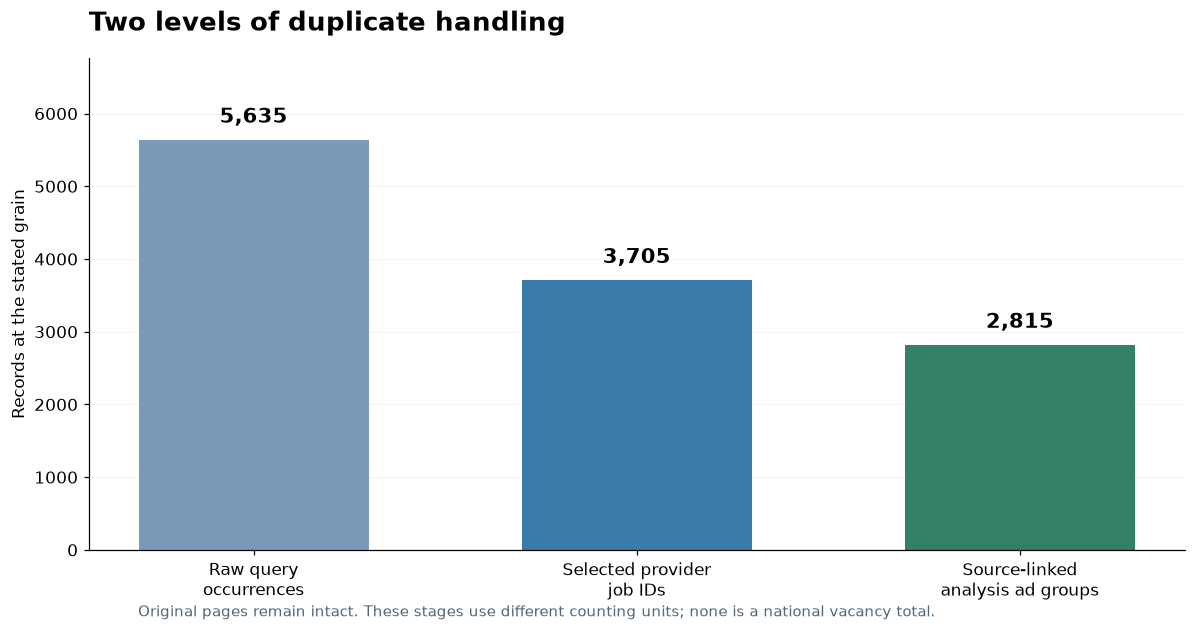

In [12]:
display(sql("""
    WITH example AS (SELECT entity_id FROM clean.job_entities GROUP BY entity_id
      ORDER BY count(*) DESC,entity_id LIMIT 1)
    SELECT p.job_id,p.title,p.company,e.entity_id,e.group_size,e.identity_conflict
    FROM clean.postings p JOIN clean.job_entities e USING(batch_id,job_id)
    JOIN example x USING(entity_id) ORDER BY p.job_id LIMIT 6
"""))
counts = mongo_qa['counts']
display(cleaning_counts(FIGURES,counts['occurrences'],counts['clean_job_summaries'],counts['postgres_analysis_ad_groups']))
plt.close('all')

## 11. SQL integration: demonstrate usable analysis rows
A salary comparison requires a listed source, valid annual USD range, a supported city/state-to-metro match, a positive BLS median and one unambiguous range per ad group/metro. Explicitly remote evidence is excluded. A 2026 posting range versus May 2025 worker wages is descriptive, not a causal pay premium. Multi-metro rows are non-additive.

In [13]:
display(sql("""
    SELECT entity_id,role,occupation_mapping,metro_name,salary_min,salary_max,
           salary_midpoint,bls_annual_median_wage,salary_midpoint_minus_bls
    FROM serving.salary_comparisons ORDER BY entity_id,bls_area LIMIT 6
"""))
display(sql("""
    SELECT role,skill,ads_mentioning_skill,ads_in_role,mention_fraction,
           matched_in_onet_software_examples
    FROM serving.role_skill_comparison
    WHERE skill IN ('llm','generative ai','mlops') ORDER BY role,skill LIMIT 12
"""))

,entity_id,role,occupation_mapping,metro_name,salary_min,salary_max,salary_midpoint,bls_annual_median_wage,salary_midpoint_minus_bls
0,ad_004321df-d624-4a5b-a48d-3a15c887720c,data / bi analyst,proxy,"Dallas-Fort Worth-Arlington, TX",95000.0,105000.0,100000.0,127750.0,-27750.0
1,ad_006a432c-04ff-4357-9eba-64ba2695e28b,data / bi analyst,proxy,"New York-Newark-Jersey City, NY-NJ",79400.0,125600.0,102500.0,135980.0,-33480.0
2,ad_009ad221-d14b-4769-a93b-5e1c8d8ab3b9,ml / ai engineer,proxy,"Chicago-Naperville-Elgin, IL-IN",96800.0,145200.0,121000.0,107640.0,13360.0
3,ad_009ad221-d14b-4769-a93b-5e1c8d8ab3b9,ml / ai engineer,proxy,"New York-Newark-Jersey City, NY-NJ",96800.0,145200.0,121000.0,135980.0,-14980.0
4,ad_00de3af9-0784-4a91-84ce-5facb5db726d,ai product manager,proxy,"New York-Newark-Jersey City, NY-NJ",144500.0,230000.0,187250.0,215300.0,-28050.0
5,ad_014b3a0a-79ff-45e6-8491-b35db6fdaa27,data scientist,direct,"Dallas-Fort Worth-Arlington, TX",179400.0,204700.0,192050.0,127750.0,64300.0


,role,skill,ads_mentioning_skill,ads_in_role,mention_fraction,matched_in_onet_software_examples
0,ai product manager,generative ai,42,110,0.381818,False
1,ai product manager,llm,59,110,0.536364,False
2,ai product manager,mlops,4,110,0.036364,False
3,ai research scientist,generative ai,17,101,0.168317,False
4,ai research scientist,llm,63,101,0.623762,False
5,ai research scientist,mlops,4,101,0.039604,False
6,data / bi analyst,generative ai,27,803,0.033624,False
7,data / bi analyst,llm,29,803,0.036115,False
8,data / bi analyst,mlops,1,803,0.001245,False
9,data engineer,generative ai,46,466,0.098712,False


## 12. Before/after summary and validation
Missingness and uncertain records are preserved, not claimed to be solved by deleting them. These are actual captured results; the database retains the original evidence behind each decision.

In [14]:
display(pd.DataFrame([
    {'step':'Repeated searches','before':f"{counts['occurrences']:,} occurrences",'after':f"{counts['clean_job_summaries']:,} canonical provider records",'retained_evidence':'raw_pages + query occurrence ledger'},
    {'step':'Cross-ID repeats','before':f"{counts['clean_job_summaries']:,} provider records",'after':f"{counts['postgres_analysis_ad_groups']:,} analysis groups",'retained_evidence':'clean.job_entities membership + conflict flags'},
    {'step':'Money','before':'Nested cents; mixed periods/currencies','after':f"{counts['clean_pay_ranges']:,} typed source ranges; {counts['eligible_salary_ranges']:,} annual USD eligible",'retained_evidence':'Original money + range/status flags'},
    {'step':'Government types','before':'TEXT numbers and suppression symbols','after':'Numeric values or NULL + explicit reason','retained_evidence':'raw.oews_metro + original workbooks'},
    {'step':'Geography','before':'Nested locations, including foreign/unknown','after':'Location rows + verified/unknown metro status','retained_evidence':'Original arrays; no guessed metro'},
]))
checks = pd.DataFrame([
    {'validation':'PostgreSQL','check':k,'passed':v} for k,v in pg_qa['checks'].items()
] + [
    {'validation':'MongoDB / cross-store','check':k,'passed':v} for k,v in mongo_qa['checks'].items()
])
display(checks)
assert checks['passed'].all()
assert db.raw_pages.count_documents({'source_snapshot':snapshot}) == counts['pages']
assert db.clean_job_summaries.count_documents(scope) == counts['clean_job_summaries']
assert db.clean_pay_ranges.count_documents(scope) == counts['clean_pay_ranges']
print('All displayed checks pass; raw pages and PostgreSQL derivatives remain stored.')

,step,before,after,retained_evidence
0,Repeated searches,"5,635 occurrences","3,705 canonical provider records",raw_pages + query occurrence ledger
1,Cross-ID repeats,"3,705 provider records","2,815 analysis groups",clean.job_entities membership + conflict flags
2,Money,Nested cents; mixed periods/currencies,"27,771 typed source ranges; 23,388 annual USD eligible",Original money + range/status flags
3,Government types,TEXT numbers and suppression symbols,Numeric values or NULL + explicit reason,raw.oews_metro + original workbooks
4,Geography,"Nested locations, including foreign/unknown",Location rows + verified/unknown metro status,Original arrays; no guessed metro


,validation,check,passed
0,PostgreSQL,all_original_files_unchanged,True
1,PostgreSQL,one_row_per_clean_job,True
2,PostgreSQL,serving_join_preserves_jobs,True
3,PostgreSQL,accepted_plus_excluded_equals_unique_raw,True
4,PostgreSQL,occurrences_reconcile,True
5,PostgreSQL,no_bls_join_duplicates,True
6,PostgreSQL,both_bls_geographies_loaded,True
7,PostgreSQL,skills_have_parent_job,True
8,PostgreSQL,source_postings_have_parent_job,True
9,PostgreSQL,money_has_parent_posting,True


All displayed checks pass; raw pages and PostgreSQL derivatives remain stored.


## 13. Exact access points and five-minute video path
The following locators intentionally omit credentials. Keep them in your local `.env`. Access from this machine is verified; teammates still need their own authorized network/database access.

Suggested recording: **0:00–0:35** section 1 storage diagram; **0:35–1:10** original JSON and collection counts; **1:10–2:10** sections 4–6 MongoDB cleaning and cents example; **2:10–3:00** BLS/O*NET before/after; **3:00–4:05** duplicate grouping and schema; **4:05–5:00** integrated rows, QA and sampling limits.

In [15]:
display(pd.DataFrame([
    {'system':'PostgreSQL','host':access['postgresql']['host'],'port':access['postgresql']['port'],'database':access['postgresql']['database']},
    {'system':'MongoDB Atlas','host':access['mongodb']['host'],'port':'Atlas SRV driver discovery','database':access['mongodb']['database']}
]))
display(pd.DataFrame([{'MongoDB collection':name,'purpose':purpose} for purpose,name in access['mongodb']['collections'].items()]))
print('Current Mongo filters:',scope)
print('Current PostgreSQL batch:',mongo_qa['postgres_batch_id'])
print('Connection credentials: local .env only.')
mongo_client.close()
engine.dispose()

,system,host,port,database
0,PostgreSQL,ai-job-market-group07.c3ckyiegwuxb.us-east-2.rds.amazonaws.com,5432,ai_job_market
1,MongoDB Atlas,aijobmarketcluster.7irkp1a.mongodb.net,Atlas SRV driver discovery,ai_job_market


,MongoDB collection,purpose
0,raw_pages,raw
1,collection_manifests,source_metadata
2,clean_job_summaries,processed_jobs
3,clean_pay_ranges,processed_salary


Current Mongo filters: {'source_snapshot': 'hc_source_eea46d64c7da954d7bab', 'clean_version': 'mc_e6b15bd4d4ef57ed176b'}
Current PostgreSQL batch: hc_c23c7bb86f43c8505bb8
Connection credentials: local .env only.


## Rebuild stored data only when needed
Notebook preview cells show progressive transformations directly. Production scripts/SQL remain the versioned implementation so a recording notebook cannot accidentally replace raw data or drift from the pipeline. No separate SQL-editor execution is needed to read this walkthrough.

From the repository root:
```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-notebook.txt
.\.venv\Scripts\python.exe scripts/ingest_reference.py
.\.venv\Scripts\python.exe scripts/transform_headcount.py
.\.venv\Scripts\python.exe scripts/ingest_headcount_mongo.py
.\.venv\Scripts\python.exe scripts/audit_data.py
.\.venv\Scripts\python.exe scripts/audit_mongodb.py
.\.venv\Scripts\python.exe scripts/build_walkthrough.py
```

The MongoDB production pipelines end in `$merge` to **clean_job_summaries** and **clean_pay_ranges**, never `raw_pages`. [MongoDB aggregation documentation](https://www.mongodb.com/docs/manual/core/aggregation-pipeline/) explains that ordinary aggregation previews do not modify collections; `$merge` explicitly persists derived output.

Full collection/cleaning rationale and access instructions: `docs/DATA_COLLECTION_AND_CLEANING_GUIDE.md`. Detailed limitations: `docs/MILESTONE2_DATA_AUDIT.md`. Schema/grains: `docs/DATA_DICTIONARY.md`. Raw file checksums: `reports/raw_file_manifest.json`.